# 1. O PICO-8 e o dataset

**Pergunta deste notebook:** o que é, exatamente, uma "música de PICO-8", e como ela chega até nós?

O PICO-8 é um console de fantasia: jogos pequenos, com limites rígidos de propósito. A música também é limitada, e é isso que torna o problema tratável:

| Peça | O que é | Limite |
|---|---|---|
| **Nota** | altura (pitch), instrumento, volume e efeito | pitch 0 a 63, 8 instrumentos, volume 0 a 7, 8 efeitos |
| **SFX** | uma fileira de notas, todas com a mesma duração | 32 notas; a velocidade (`speed`) diz quantos ticks dura cada nota |
| **Pattern** | até 4 SFX tocando juntos, um por canal | 4 canais |
| **Música** | uma sequência de patterns, com marcas de loop | até 64 patterns por jogo |

Não existe áudio gravado: a música é uma **partitura** (dados simbólicos) que o console sintetiza na hora. Por isso modelamos a partitura, e não o som.

Os notebooks usam o código da `main` (`src/`, `evaluation/`) e a pasta do Drive em `artefatos/` (veja o `README.md` desta pasta).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nbkit as k

k.estilo()
reais = k.musicas_reais(300)       # 300 das 1.854 músicas reais do conjunto de teste
musica = reais[154]
print(f"{len(reais)} músicas carregadas")
print("campos de uma música:", [c for c in musica if c != "patterns"])
print(f"exemplo: jogo {musica['tid']}, {musica['num_patterns']} patterns, {k.duracao(musica):.0f} s")

300 músicas carregadas
campos de uma música: ['song_id', 'wav_file', 'start_pattern', 'end_pattern', 'loop_start_pattern', 'end_reason', 'num_patterns', 'total_ticks', 'duration_sec', 'uses_custom_instruments', 'blocks_dictionary', 'tid']
exemplo: jogo 27788, 6 patterns, 25 s


## A música como o editor do PICO-8 mostra

Cada linha é um passo do pattern; cada coluna, um canal. Em cada célula: nota, instrumento (`i`), volume (`v`) e efeito (`f`). É o mesmo formato de "tracker" usado em chiptune desde os anos 80.

In [2]:
print(k.tracker(musica, pattern=0, passos=16))

passo | canal 1       | canal 2       | canal 3       | canal 4      
------------------------------------------------------------------
    0 | fá1   i2 v3 f7 | fá0   i0 v5 f0 | lá1   i0 v5 f3 | ·             
    1 | lá1   i2 v2 f7 | ·              | ·              | ·             
    2 | dó2   i2 v1 f7 | fá1   i0 v5 f0 | ·              | ·             
    3 | lá1   i2 v1 f7 | ·              | ·              | ·             
    4 | fá1   i2 v3 f7 | fá0   i0 v5 f0 | lá2   i6 v3 f3 | ·             
    5 | lá1   i2 v2 f7 | ·              | ·              | ·             
    6 | dó2   i2 v1 f7 | fá1   i0 v5 f0 | ·              | ·             
    7 | lá1   i2 v1 f7 | ·              | ·              | ·             
    8 | fá1   i2 v3 f7 | fá0   i0 v5 f0 | lá1   i0 v5 f3 | ·             
    9 | lá1   i2 v2 f7 | ·              | ·              | ·             
   10 | dó2   i2 v1 f7 | fá1   i0 v5 f0 | lá1   i0 v5 f3 | ·             
   11 | lá1   i2 v1 f7 | ·              | ·      

## A mesma música como piano roll

O piano roll é a figura que vamos usar nos outros notebooks: o eixo horizontal é o tempo, o vertical é a altura da nota e a cor é o canal.

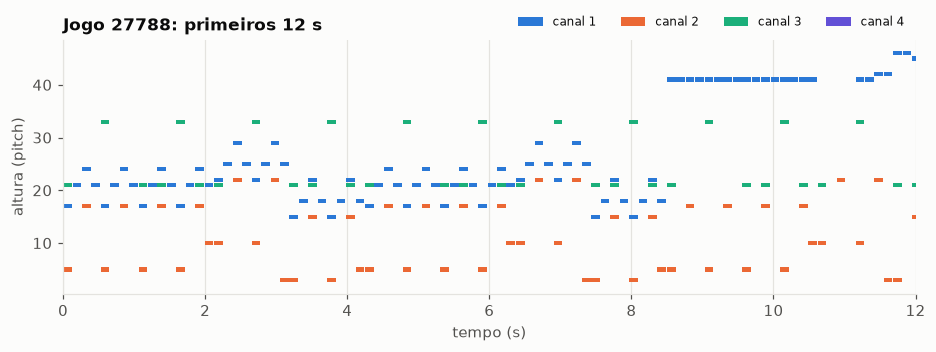

In [3]:
k.piano_roll(musica, segundos=12, titulo=f"Jogo {musica['tid']}: primeiros 12 s")
plt.show()

## E como som

O `src/synth.py` reproduz o sintetizador do PICO-8. O player abaixo toca os primeiros 8 segundos.

In [4]:
k.tocar(musica)

## Os 8 instrumentos

Cada instrumento é uma forma de onda fixa. O instrumento 6 é ruído (usado como percussão) e não tem forma fixa.

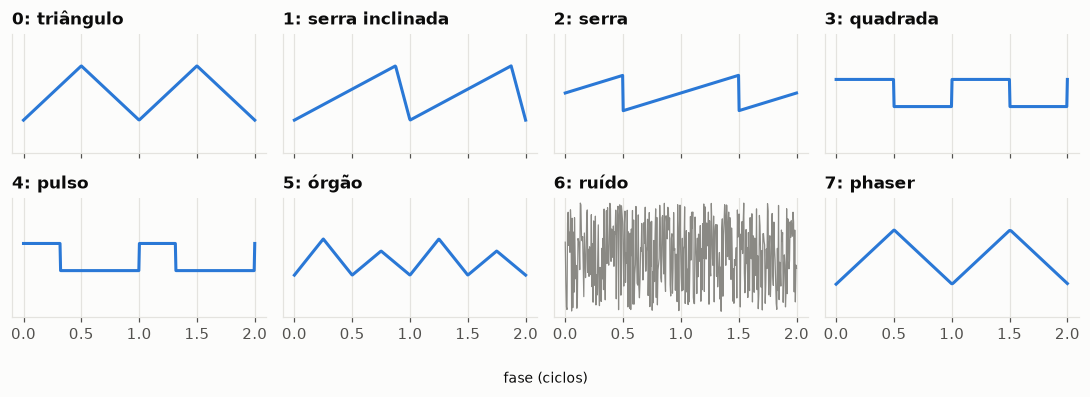

In [5]:
from synth import waveform

fase = np.linspace(0, 2, 400)
fig, axes = plt.subplots(2, 4, figsize=(10, 3.6), sharex=True, sharey=True)
for inst, ax in enumerate(axes.flat):
    if inst == 6:
        ax.plot(fase, np.random.default_rng(0).uniform(-1, 1, fase.size), color=k.CINZA, lw=0.8)
    else:
        ax.plot(fase, waveform(inst, fase), color=k.AZUL, lw=2)
    ax.set_title(f"{inst}: {k.INSTRUMENTOS[inst]}", loc="left")
    ax.set_yticks([])
fig.supxlabel("fase (ciclos)", fontsize=9)
fig.tight_layout()
plt.show()

## Os 8 efeitos

O efeito muda como a nota soa ao longo da sua duração. Abaixo, a mesma nota tocada com cada efeito, em ordem: nenhum, slide, vibrato, drop, fade in, fade out, arpejo rápido e arpejo lento (o arpejo alterna entre notas vizinhas, por isso usamos quatro notas diferentes).

In [6]:
from synth import PICO_RATE, synthesize_notes

seq = []
for efeito in range(8):
    alturas = [24, 28, 31, 36] if efeito >= 6 else [24, 31, 31, 31]
    seq += [{"pitch": p, "instrument": 0, "volume": 5, "effect": efeito} for p in alturas]
    seq += [{"pitch": 0, "instrument": 0, "volume": 0, "effect": 0}] * 2      # pausa
k.audio(synthesize_notes(seq, speed=16, rate=PICO_RATE), PICO_RATE)

Esses efeitos **por nota** fazem parte da partitura e entram nos tokens (notebook 3). Já os filtros de SFX (reverb, dampen, etc.) valem para um SFX inteiro e ficam fora da partitura que modelamos.

## Como são as músicas do dataset

O dataset reúne as músicas de milhares de jogos publicados. Três medidas simples nas 300 músicas carregadas:

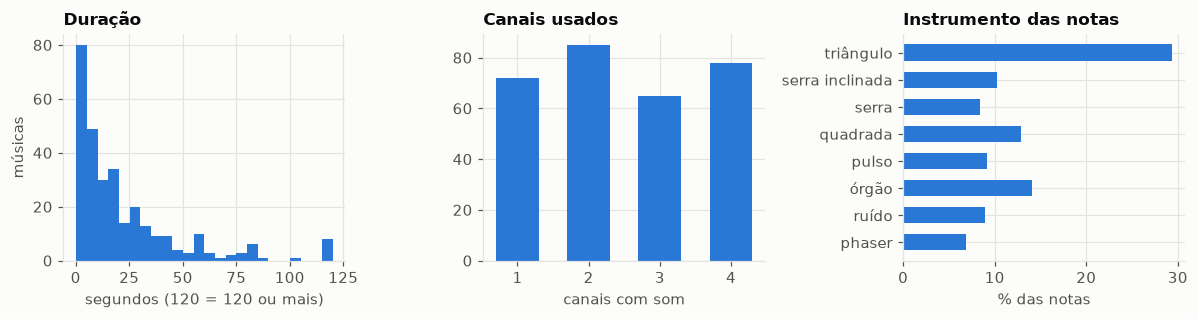

duração mediana: 13 s


In [7]:
from collections import Counter

dur = [k.duracao(m) for m in reais]
canais = [len({n[0] for n in k.notas(m)}) for m in reais]
inst = Counter(n[4] for m in reais for n in k.notas(m))

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].hist(np.clip(dur, 0, 120), bins=24, color=k.AZUL)
ax[0].set_title("Duração", loc="left"); ax[0].set_xlabel("segundos (120 = 120 ou mais)"); ax[0].set_ylabel("músicas")
ax[1].bar(range(1, 5), [canais.count(c) for c in range(1, 5)], color=k.AZUL, width=0.6)
ax[1].set_title("Canais usados", loc="left"); ax[1].set_xlabel("canais com som"); ax[1].set_xticks(range(1, 5))
total = sum(inst.values())
ax[2].barh([k.INSTRUMENTOS[i] for i in range(8)], [100 * inst[i] / total for i in range(8)], color=k.AZUL, height=0.6)
ax[2].invert_yaxis(); ax[2].set_title("Instrumento das notas", loc="left"); ax[2].set_xlabel("% das notas")
fig.tight_layout()
plt.show()
print(f"duração mediana: {np.median(dur):.0f} s")

## O que levar daqui

- Uma música de PICO-8 é uma partitura pequena e discreta: 4 canais, 64 alturas, 8 instrumentos, 8 efeitos.
- Tudo o que o modelo precisa aprender cabe nesses poucos símbolos, o que permite treinar uma rede pequena.
- Há muita música curta (jingles de poucos segundos) e nem todas usam os 4 canais.

**Experimente:** troque `reais[154]` por outro índice; mude `pattern=0` no tracker; troque `"instrument": 0` na célula dos efeitos por outro instrumento.

Próximo: [2. Filtros e divisão dos dados](02_filtros_e_split.ipynb).